# Backtests: Kupiec, Christoffersen, the duration test, dynamic quantile and the Basel traffic light

- **Level:** 2, The method in practice
- **Prerequisites:** notebook 01 of this topic (VaR, ES and a first exceedance count)
- **Reading time:** about 50 minutes

**Question:** When a crisis forecast fails its 1 percent VaR, does it fail because there are too many exceedances, because they come in bunches or because they can be predicted, and what does the Basel traffic light say about the same count?

## Objectives

By the end of this notebook you can:

- state the null hypothesis, the statistic and the distribution of the Kupiec, Christoffersen, duration and dynamic quantile tests, and compute the first two from their closed forms;
- explain why the exact binomial p-value matters when the expected number of exceedances is small, and show it on a 250-day window at the 1 percent level;
- read the Basel traffic light as a cumulative binomial probability, and compute its zones and multipliers on a rolling window;
- run the whole exceedance battery on the 17 models of a crisis window and read which tests flag a wrong count and which flag clustered or predictable exceedances.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.1.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The next cell imports the packages and prints their versions.

In [1]:
# Import the tools and print the versions they run with, and fix the words this notebook prints for the
# engine's lights
import importlib.metadata as md
import json
import math
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from scipy import special, stats

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

LIGHT = {"green": "green", "amber": "amber", "red": "red", "not_evaluated": "not evaluated"}

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Data

The data is case C11 as Contraste commits it: four windows of the market-risk back-test, each holding the VaR path and the exceedance days of 17 models at the tail levels 1 and 2.5 percent.

- `calm-2004-06`: three calm years, 750 forecast days (the control window).
- `equity-2007-09`: the financial crisis, 504 days.
- `equity-2020`: the pandemic crash, 104 days.
- `rates-2022`: the hiking cycle, a 10-year Treasury position, 249 days.

All four store the days on which the loss exceeded the VaR, which is all the exceedance tests read. The tests use **flags** (1 on an exceedance day), so the notebook rebuilds the flags from the stored days and the VaR path from the committed file. The next cell loads the windows and defines the one reader the notebook uses.

In [2]:
# Load the four windows and define the reader that returns the exceedance flags and the VaR path of one
# model and level
ROOT = Path("../../..").resolve()
WINDOWS = ("calm-2004-06", "equity-2007-09", "equity-2020", "rates-2022")
C11 = ROOT / "data" / "derived" / "C11"
windows = {w: json.loads((C11 / f"{w}.json").read_text(encoding="utf-8")) for w in WINDOWS}


def series_of(window, model_id, alpha):
    """Flags and VaR path (loss numbers) of one model and level."""
    model = {m["model_id"]: m for m in windows[window]["outputs"]["models"]}[model_id]
    level = [lv for lv in model["by_level"] if lv["alpha"] == alpha][0]
    flags = np.zeros(level["n_scored"], dtype=bool)
    flags[level["exceedance_days"]] = True
    return flags, np.array(level["var"])


for w in WINDOWS:
    flags, var = series_of(w, "hs-250", 0.01)
    print(f"{w:15s} days {flags.size:4d} | hs-250: {int(flags.sum()):3d} exceedances at 1%, "
          f"expected {0.01 * flags.size:5.2f}")

calm-2004-06    days  750 | hs-250:   9 exceedances at 1%, expected  7.50
equity-2007-09  days  504 | hs-250:  19 exceedances at 1%, expected  5.04
equity-2020     days  104 | hs-250:   8 exceedances at 1%, expected  1.04
rates-2022      days  249 | hs-250:   8 exceedances at 1%, expected  2.49


## Method

### Step 1: Kupiec's proportion of failures

If the VaR is right the exceedance indicator $I_t$ is a sequence of independent Bernoulli($\alpha$) variables, so $x = \sum_t I_t$ in $T$ days is binomial($T$, $\alpha$). Kupiec (1995) tests $H_0: \Pr(I_t = 1) = \alpha$ with the likelihood ratio of the observed share $\hat\pi = x/T$ against $\alpha$, using the convention $0\ln 0 = 0$:

$$LR_{POF} = -2\ln\frac{(1-\alpha)^{T-x}\,\alpha^{x}}{(1-\hat\pi)^{T-x}\,\hat\pi^{x}} \;\xrightarrow{d}\; \chi^2_1$$

The engine's `kupiec_pof` returns the statistic, the asymptotic p-value and, in `metric`, the exact binomial p-value: the total probability, under binomial($T$, $\alpha$), of the counts that are at most as likely as the observed $x$. The cell computes both p-values from the definitions for `hs-250` in the crisis and prints them beside the engine's.

In [3]:
# Kupiec by hand from the definition (statistic, asymptotic and exact p-values) and by the engine, for
# hs-250 in the crisis
from riskvalidation.validation.market import kupiec_pof

alpha = 0.01
flags, var = series_of("equity-2007-09", "hs-250", alpha)
T, x = flags.size, int(flags.sum())
pi_hat = x / T
log_null = (T - x) * math.log(1 - alpha) + special.xlogy(x, alpha)
log_alternative = (T - x) * math.log(1 - pi_hat) + special.xlogy(x, pi_hat)
lr = -2.0 * (log_null - log_alternative)
pmf = stats.binom.pmf(np.arange(T + 1), T, alpha)
p_exact = pmf[pmf <= pmf[x] * (1 + 1e-7)].sum()
print(f"T {T}, x {x}, expected {alpha * T:.2f}, observed share {pi_hat:.4f}")
print(f"by hand: LR {lr:.4f} | p asymptotic {stats.chi2.sf(lr, 1):.3e} | p exact {p_exact:.3e}")
engine = kupiec_pof(flags, alpha, model_id="hs-250")
print(f"engine: LR {engine.statistic:.4f} | p asymptotic {engine.p_value:.3e} | p exact {engine.metric:.3e}")
print(f"light: {LIGHT[engine.light.value]}")

T 504, x 19, expected 5.04, observed share 0.0377
by hand: LR 22.9015 | p asymptotic 1.705e-06 | p exact 1.303e-06
engine: LR 22.9015 | p asymptotic 1.705e-06 | p exact 1.303e-06
light: red


### Step 2: when the expected count is small

On a 250-day window at the 1 percent level the expected count is 2.5. The chi-square law is then a poor approximation of a discrete statistic that can only take a few values, and the asymptotic and the exact p-values can sit on opposite sides of a threshold. The next cell builds a 250-day flag series with $x$ exceedances for $x = 0,\dots,10$, runs `kupiec_pof` on each and draws both p-values. The Contraste gate colours a result amber below 0.10 and red below 0.05 on the asymptotic p-value; it is an internal convention, not a regulatory threshold.

x 0: p asymptotic 0.0250 | p exact 0.1889 | light red
x 6: p asymptotic 0.0594 | p exact 0.0412 | light amber


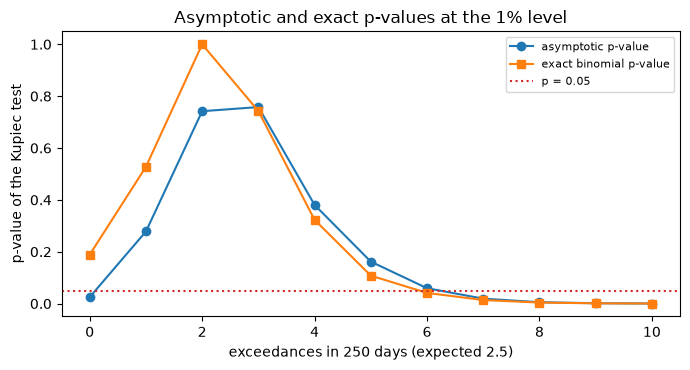

In [4]:
# Asymptotic against exact p-value of the Kupiec test for every count from 0 to 10 in a 250-day window at
# the 1% level
counts = np.arange(11)
results = [kupiec_pof(np.arange(250) < c, 0.01) for c in counts]
asymptotic = np.array([r.p_value for r in results])
exact = np.array([r.metric for r in results])
for c in (0, 6):
    print(f"x {c}: p asymptotic {asymptotic[c]:.4f} | p exact {exact[c]:.4f} | light {LIGHT[results[c].light.value]}")

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(counts, asymptotic, marker="o", label="asymptotic p-value")
ax.plot(counts, exact, marker="s", label="exact binomial p-value")
ax.axhline(0.05, color="tab:red", linestyle=":", label="p = 0.05")
ax.set_xlabel("exceedances in 250 days (expected 2.5)")
ax.set_ylabel("p-value of the Kupiec test")
ax.set_title("Asymptotic and exact p-values at the 1% level")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

The two curves cross the 0.05 line at different counts. With no exceedance at all the asymptotic p-value is 0.0250 and the gate colours the forecast red, yet the exact p-value is 0.1889: with 2.5 exceedances expected, seeing none is weak evidence against the model. At 6 exceedances the asymptotic p-value is 0.0594 (amber) and the exact one 0.0412, on the other side of the line. The jaggedness of the exact curve is real, since a binomial count can only take whole values. The figure shows that the asymptotic p-value can accuse a correct forecast and acquit a wrong one when the expected count is small, so the exact p-value is the one to read beside it whenever the expected count is under about ten.

### Step 3: Christoffersen's independence and conditional coverage

A model can have the right number of exceedances and still be wrong if they come in bunches. Christoffersen (1998) tests the exceedance sequence against a first-order Markov chain. Let $n_{ij}$ be the number of days on which state $i$ was followed by state $j$ ($0$ no exceedance, $1$ exceedance), $\pi_{01} = n_{01}/(n_{00}+n_{01})$, $\pi_{11} = n_{11}/(n_{10}+n_{11})$ and $\pi = (n_{01}+n_{11})/(n_{00}+n_{01}+n_{10}+n_{11})$:

$$LR_{ind} = -2\ln\frac{(1-\pi)^{n_{00}+n_{10}}\,\pi^{n_{01}+n_{11}}}{(1-\pi_{01})^{n_{00}}\,\pi_{01}^{n_{01}}\,(1-\pi_{11})^{n_{10}}\,\pi_{11}^{n_{11}}} \xrightarrow{d} \chi^2_1, \qquad LR_{cc} = LR_{POF} + LR_{ind} \xrightarrow{d} \chi^2_2$$

Independence holds when $\pi_{01} = \pi_{11}$: an exceedance does not change tomorrow's chance of another. The cell counts the transitions of the `garch-t` flags in the crisis at 2.5 percent, computes the statistics by hand, and compares them with `christoffersen_independence` and `christoffersen_conditional_coverage`.

In [5]:
# Transition counts and the Christoffersen statistics by hand and by the engine, for garch-t in the crisis
# at 2.5%
from riskvalidation.validation.market import christoffersen_conditional_coverage, christoffersen_independence

alpha = 0.025
flags, var = series_of("equity-2007-09", "garch-t", alpha)
before, after = flags[:-1], flags[1:]
n00, n01 = int(np.sum(~before & ~after)), int(np.sum(~before & after))
n10, n11 = int(np.sum(before & ~after)), int(np.sum(before & after))
pi01, pi11 = n01 / (n00 + n01), n11 / (n10 + n11)
pi = (n01 + n11) / (n00 + n01 + n10 + n11)
print(f"transitions: n00 {n00}, n01 {n01}, n10 {n10}, n11 {n11}")
print(f"P(1 | 0) {pi01:.4f} | P(1 | 1) {pi11:.4f} | unconditional {pi:.4f}")
null = special.xlogy(n00 + n10, 1 - pi) + special.xlogy(n01 + n11, pi)
alternative = special.xlogy(n00, 1 - pi01) + special.xlogy(n01, pi01)
alternative += special.xlogy(n10, 1 - pi11) + special.xlogy(n11, pi11)
lr_ind = -2.0 * (null - alternative)
print(f"by hand: LR_ind {lr_ind:.4f} | p {stats.chi2.sf(lr_ind, 1):.4f}")
ind = christoffersen_independence(flags, alpha, model_id="garch-t")
cc = christoffersen_conditional_coverage(flags, alpha, model_id="garch-t")
print(f"engine: LR_ind {ind.statistic:.4f} p {ind.p_value:.4f} {LIGHT[ind.light.value]}")
print(f"conditional coverage: LR_cc {cc.statistic:.4f} = {cc.extras['lr_pof']:.4f} + {cc.extras['lr_ind']:.4f}")

transitions: n00 441, n01 31, n10 31, n11 0
P(1 | 0) 0.0657 | P(1 | 1) 0.0000 | unconditional 0.0616
by hand: LR_ind 4.0750 | p 0.0435
engine: LR_ind 4.0750 p 0.0435 red
conditional coverage: LR_cc 23.7907 = 19.7157 + 4.0750


For `garch-t` in the crisis at 2.5 percent there are 31 days with an exceedance and none of them was followed by another the next day: $P(1\mid 1)$ is 0.0000 against $P(1\mid 0)$ of 0.0657. The independence statistic is 4.0750 (p 0.0435, red), and conditional coverage splits as 23.7907 = 19.7157 + 4.0750, so most of the rejection comes from the count and the independence part is small. The rejection of independence here is the opposite of bunching: exceedances that never land on consecutive days. The test looks only one step ahead and cannot say whether longer gaps are irregular, which is what the duration test of the next step looks at.

### Step 4: the duration test

The independence test looks only one day ahead. Christoffersen and Pelletier (2004) look at the **durations** $D_i$, the days between consecutive exceedances. If coverage is right and the exceedances are independent, the durations are memoryless (geometric, close to exponential), and the probability of an exceedance does not depend on the time since the last one. They model the hazard as Weibull, $\lambda(d) = a^b\,b\,d^{\,b-1}$, with $b = 1$ under the null, so $b < 1$ is a decreasing hazard (bunching) and $b > 1$ an increasing one (too regular). The statistic is the likelihood ratio of $b = 1$, with the first and last spells censored, and its p-value is by Monte Carlo (draws of Bernoulli($\alpha$) sequences of the same length). The cell lists the completed durations of `hs-250` in the crisis at 1 percent, runs `duration_test` with 10,000 draws and a fixed seed, and draws the durations against the geometric histogram the null predicts.

exceedances 19 | completed durations 18 | mean 19.1 days | expected under the null 100
LR 5.1768 | Weibull b 0.690 | p 0.0824
light: amber


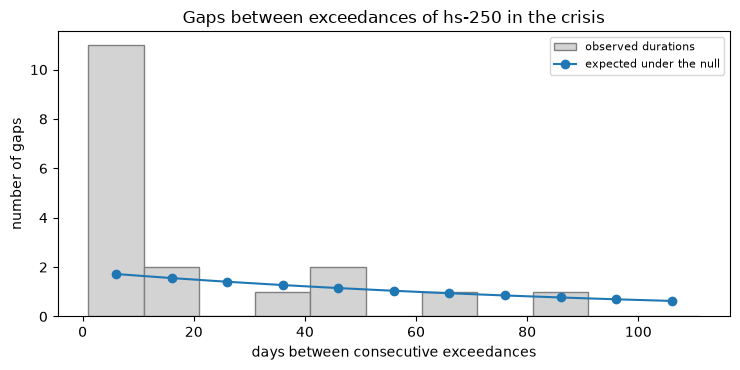

In [6]:
# Durations between exceedances, the duration test with 10,000 draws, and the geometric histogram the null
# predicts
from riskvalidation.validation.market import duration_test

alpha = 0.01
flags, var = series_of("equity-2007-09", "hs-250", alpha)
durations = np.diff(np.flatnonzero(flags))
result = duration_test(flags, alpha, model_id="hs-250", n_mc=10000, seed=42)
print(f"exceedances {flags.sum()} | completed durations {durations.size} | "
      f"mean {durations.mean():.1f} days | expected under the null {1 / alpha:.0f}")
print(f"LR {result.statistic:.4f} | Weibull b {result.extras['weibull_b']:.3f} | p {result.p_value:.4f}")
print(f"light: {LIGHT[result.light.value]}")

edges = np.arange(1, 112, 10)
expected = durations.size * ((1 - alpha) ** (edges[:-1] - 1) - (1 - alpha) ** (edges[1:] - 1))
fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.hist(durations, bins=edges, color="lightgrey", edgecolor="grey", label="observed durations")
ax.plot((edges[:-1] + edges[1:]) / 2, expected, marker="o", color="tab:blue", label="expected under the null")
ax.set_xlabel("days between consecutive exceedances")
ax.set_ylabel("number of gaps")
ax.set_title("Gaps between exceedances of hs-250 in the crisis")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

The grey bars are the gaps between the 19 exceedances of `hs-250` in the crisis and the blue line is what a correct forecast with independent exceedances would give, about 1.7 gaps in each bin of 10 days. Eleven of the 18 gaps fall within the first 10 days, a bunching the geometric law does not expect, while the mean gap is 19.1 days where the null expects 100. The Weibull shape is 0.690 (below 1: a falling hazard), the statistic 5.1768 and the Monte Carlo p-value 0.0824, amber. The same forecast has a Kupiec p-value of 1.705e-06 and is only amber here: the tests answer different questions, and with 18 gaps the duration test has little power.

### Step 5: the dynamic quantile test

Engle and Manganelli (2004) ask whether the exceedances are **predictable** from anything known the day before. Regress the demeaned hit $\mathrm{Hit}_t = I_t - \alpha$ on a constant, four lagged hits and the current VaR, collected in the matrix $X$. Under correct conditional coverage no coefficient differs from zero, and the quadratic form

$$DQ = \frac{\mathrm{Hit}^{\top} X\,(X^{\top}X)^{+}\,X^{\top}\mathrm{Hit}}{\alpha(1-\alpha)}$$

is asymptotically chi-square with the rank of $X$ degrees of freedom. With sparse hits that law is poor: the engine records that the plain test rejected correct forecasts far more often than 5 percent, so its light follows a **Monte Carlo p-value** and the asymptotic one stays in `extras`. The cell computes the quadratic form by hand from the definition on the `hs-250` flags and compares it with the engine's statistic and p-values.

In [7]:
# The dynamic quantile statistic by hand (4 lags) and the engine's statistic with its Monte Carlo and
# asymptotic p-values
from riskvalidation.validation.market import dynamic_quantile_test

lags = 4
hits = flags.astype(float)
lagged = [hits[lags - j:hits.size - j] for j in range(1, lags + 1)]
X = np.column_stack([np.ones(hits.size - lags)] + lagged + [var[lags:]])
hit_demeaned = hits[lags:] - alpha
dq_by_hand = float(hit_demeaned @ X @ np.linalg.pinv(X.T @ X) @ X.T @ hit_demeaned) / (alpha * (1 - alpha))
print(f"regression: {X.shape[0]} days, {X.shape[1]} columns, rank {np.linalg.matrix_rank(X)}")
print(f"by hand: DQ {dq_by_hand:.4f}")
engine = dynamic_quantile_test(flags, var, alpha, lags=lags, model_id="hs-250", n_mc=10000, seed=42)
print(f"engine: DQ {engine.statistic:.4f} | p Monte Carlo {engine.p_value:.4f} | "
      f"p asymptotic {engine.extras['p_value_asymptotic']:.4f} | {LIGHT[engine.light.value]}")

regression: 500 days, 6 columns, rank 6
by hand: DQ 121.1612
engine: DQ 121.1612 | p Monte Carlo 0.0003 | p asymptotic 0.0000 | red


### Step 6: the Basel traffic light

The 1996 Basel framework judges a bank's 99 percent VaR by the number of exceptions $k$ in the last 250 trading days. Under a correct model $k \sim$ binomial(250, 0.01), and the zones are cut on the cumulative probability $P(X \le k)$: **green** below the count where it first reaches 95 percent, **amber** from there, **red** from the count where it reaches 99.99 percent. The multiplier $m_c$ of the capital charge rises with the zone (MAR32.9 Table 1). The engine has the three pieces as functions: `binomial_cumulative_probability`, `traffic_light_zone` and `mar32_multiplier`. The cell evaluates them for 0 to 12 exceptions and draws the cumulative probability coloured by zone beside the multiplier. The multiplier is the backtesting-dependent $m_c$ of MAR32.9, 1.50 to 2.00; the committed ladder document lists beside it the older US factor of 3.00 to 4.00.

k 4: P(X <= k) 89.2188% | zone green | multiplier 1.50
k 5: P(X <= k) 95.8817% | zone amber | multiplier 1.70
k 9: P(X <= k) 99.9750% | zone amber | multiplier 1.92
k 10: P(X <= k) 99.9946% | zone red | multiplier 2.00


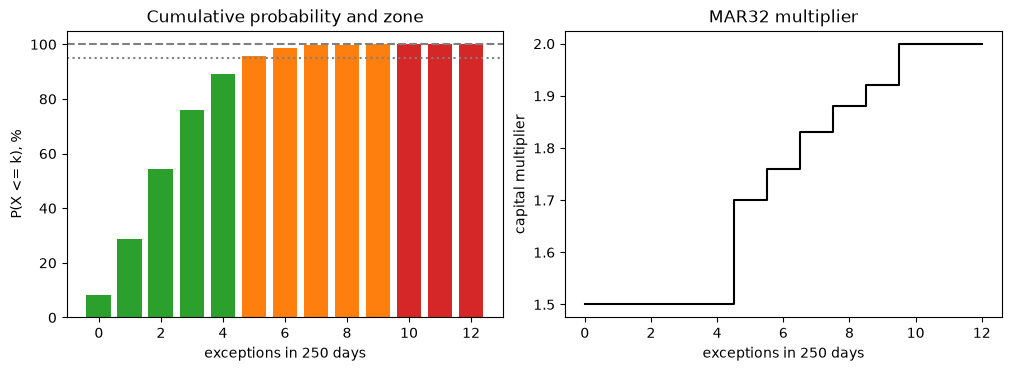

In [8]:
# The traffic-light table for 0 to 12 exceptions in 250 days at 99% coverage: cumulative probability, zone
# and multiplier
from riskvalidation.market.frtb import binomial_cumulative_probability, mar32_multiplier, traffic_light_zone

ks = np.arange(13)
cumulative = np.array([binomial_cumulative_probability(int(k), 250, 0.01) for k in ks])
zones = [traffic_light_zone(int(k)) for k in ks]
multiplier = np.array([mar32_multiplier(int(k)) for k in ks])
for k in (4, 5, 9, 10):
    print(f"k {k}: P(X <= k) {100 * cumulative[k]:.4f}% | zone {LIGHT[zones[k]]} | multiplier {multiplier[k]:.2f}")

colour = {"green": "tab:green", "amber": "tab:orange", "red": "tab:red"}
fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3.6), layout="constrained")
left.bar(ks, 100 * cumulative, color=[colour[z] for z in zones])
left.axhline(95, color="grey", linestyle=":")
left.axhline(99.99, color="grey", linestyle="--")
left.set_xlabel("exceptions in 250 days")
left.set_ylabel("P(X <= k), %")
left.set_title("Cumulative probability and zone")
right.step(ks, multiplier, where="mid", color="black")
right.set_xlabel("exceptions in 250 days")
right.set_ylabel("capital multiplier")
right.set_title("MAR32 multiplier")
plt.show()

Up to 4 exceptions the cumulative probability is below 95 percent (89.2188 percent at 4) and the zone is green with a multiplier of 1.50. At 5 exceptions it reaches 95.8817 percent and the zone turns amber with a multiplier of 1.70; at 9 it is 99.9750 percent and 1.92; from 10 exceptions (99.9946 percent) the zone is red and the multiplier 2.00. The dotted line marks 95 percent and the dashed one 99.99 percent. The figure shows that the zones are probabilities under the null and not a count chosen by judgement, and that the multiplier climbs smoothly through the amber zone before it saturates. It does not say what a bank should do with an amber result: that is a supervisory decision outside the engine.

The light is a function of the last 250 days, so over a longer window it can be computed on every rolling window. The next cell counts, for `hs-250` and `ewma` in the crisis, the exceptions in each rolling window of 250 days, assigns each window its zone with `traffic_light_zone` and asks the engine's `basel_traffic_light` for the light of the last window. The figure draws the rolling count against the amber and red bands.

hs-250: 255 windows | maximum 14 | amber 60, red 195, green 0
  last window: 10 | P 99.9946% | red
ewma: 255 windows | maximum 12 | amber 229, red 26, green 0
  last window: 7 | P 99.5975% | amber


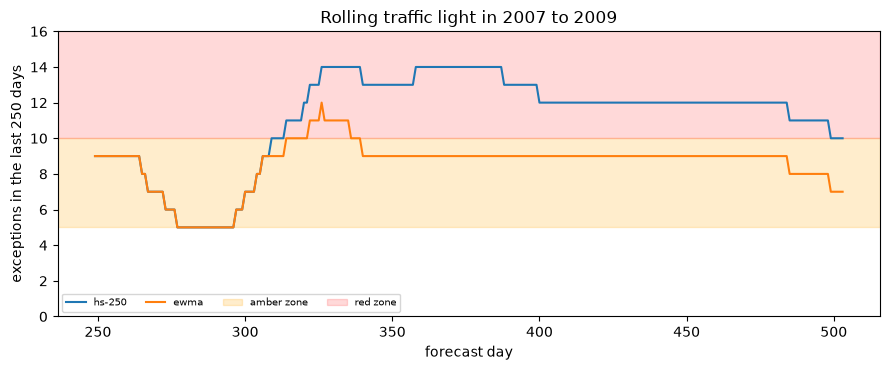

In [9]:
# Rolling 250-day exception counts of hs-250 and ewma in the crisis, their zones, and the engine's light on
# the last window
from riskvalidation.validation.market import basel_traffic_light

fig, ax = plt.subplots(figsize=(9, 3.8))
for model_id in ("hs-250", "ewma"):
    flags, var = series_of("equity-2007-09", model_id, 0.01)
    running = np.concatenate([[0], np.cumsum(flags)])
    rolling = (running[250:] - running[:-250]).astype(int)
    zone_of = [traffic_light_zone(int(k)) for k in rolling]
    light = basel_traffic_light(flags, model_id=model_id)
    ax.plot(np.arange(rolling.size) + 249, rolling, label=model_id)
    print(f"{model_id}: {rolling.size} windows | maximum {rolling.max()} | "
          f"amber {zone_of.count('amber')}, red {zone_of.count('red')}, green {zone_of.count('green')}")
    print(f"  last window: {int(light.statistic)} | P {light.metric:.4f}% | {LIGHT[light.light.value]}")
ax.axhspan(5, 10, color="orange", alpha=0.2, label="amber zone")
ax.axhspan(10, 20, color="red", alpha=0.15, label="red zone")
ax.set_ylim(0, 16)
ax.set_xlabel("forecast day")
ax.set_ylabel("exceptions in the last 250 days")
ax.set_title("Rolling traffic light in 2007 to 2009")
ax.legend(fontsize=7, ncol=4)
fig.tight_layout()
plt.show()

Both models start the crisis amber at 9 exceptions, fall to 5 around day 280 and then climb. The historical simulation `hs-250` crosses into the red zone near day 310 and stays there until the end of the window: of 255 rolling windows it is amber in 60 and red in 195, with a maximum of 14 exceptions and 10 in the last window (99.9946 percent, red). The EWMA touches the red band only briefly near day 325 (maximum 12), is amber in 229 windows and red in 26, and ends at 7 exceptions (99.5975 percent, amber). Neither model has a single green window, because 5 exceptions or more remain in every window. The figure shows how much a reactive forecast changes the light, not that the EWMA is acceptable: amber still carries a multiplier above the minimum.

### Step 7: which test sees what

A wrong count, clustered exceedances and predictable exceedances are different failures, and the battery separates them. The cell runs four of the tests live on all 17 models of the 2007 to 2009 crisis at both tail levels (Kupiec, independence, duration and dynamic quantile, the last two with 2,000 Monte Carlo draws and a fixed seed) and counts how many models each test colours red. The figure draws the counts.

alpha 0.01: [17, 0, 2, 17] models in red, tests in the order of the figure
alpha 0.025: [17, 4, 4, 17] models in red, tests in the order of the figure


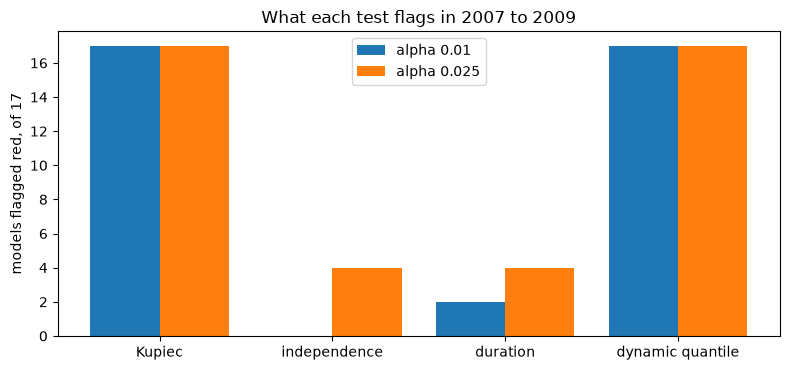

In [10]:
# Run four exceedance tests on the 17 models of the crisis window at both levels and count the models each
# one flags red
from riskvalidation.validation.market import dynamic_quantile_test

tests = ("Kupiec", "independence", "duration", "dynamic quantile")
model_ids = [m["model_id"] for m in windows["equity-2007-09"]["outputs"]["models"]]
red = np.zeros((2, len(tests)), dtype=int)
for row, alpha in enumerate((0.01, 0.025)):
    for model_id in model_ids:
        flags, var = series_of("equity-2007-09", model_id, alpha)
        lights = [
            kupiec_pof(flags, alpha, model_id).light.value,
            christoffersen_independence(flags, alpha, model_id).light.value,
            duration_test(flags, alpha, model_id, n_mc=2000, seed=42).light.value,
            dynamic_quantile_test(flags, var, alpha, lags=4, model_id=model_id, n_mc=2000, seed=42).light.value,
        ]
        red[row] += np.array(lights) == "red"
    print(f"alpha {alpha}: {red[row].tolist()} models in red, tests in the order of the figure")

fig, ax = plt.subplots(figsize=(8, 3.8))
for shift, row, alpha in ((-0.2, 0, 0.01), (0.2, 1, 0.025)):
    ax.bar(np.arange(len(tests)) + shift, red[row], width=0.4, label=f"alpha {alpha}")
ax.set_xticks(np.arange(len(tests)), tests)
ax.set_ylabel("models flagged red, of 17")
ax.set_title("What each test flags in 2007 to 2009")
ax.legend()
fig.tight_layout()
plt.show()

Kupiec flags all 17 models in red at both levels, and so does the dynamic quantile test, which asks whether the hits can be predicted from their own past and from the VaR. Independence flags none at 1 percent and 4 at 2.5 percent, and duration 2 and 4. In this crisis the dominant failure is the number of exceedances, and the sequence failures that these tests can see are the secondary one. The figure does not show that clustering is absent: a 504-day window with about 5 expected exceedances gives the independence and duration tests little to work with, which is why the engine reports their lights as internal gates and not as verdicts.

## Results

**Answer:** Mostly because there are too many of them. In the 2007 to 2009 crisis Kupiec flags all 17 models red at both tail levels (`hs-250` had 19 exceedances in 504 days against 5.04 expected, a statistic of 22.9015 and a p-value of 1.705e-06), while independence flags none at 0.01 and 4 at 0.025 and the duration test 2 and 4; the dynamic quantile test, which asks whether the hits can be predicted, also flags 17 of 17. Judged by the Basel light, `hs-250` is red in 195 of its 255 rolling windows, with at most 14 exceptions.

- **Kupiec, by hand and by engine.** The likelihood ratio is 22.9015 with an asymptotic p-value of 1.705e-06 and an exact binomial p-value of 1.303e-06, and the hand computation and the engine agree to the digits printed.
- **Small counts.** For a 250-day window at 1 percent (2.5 expected) zero exceedances give an asymptotic p-value of 0.0250, which the gate colours red, while the exact p-value is 0.1889. At 6 exceedances the asymptotic p-value is 0.0594 (amber) and the exact one 0.0412.
- **Independence.** For `garch-t` at 0.025 there are 31 exceedance days and none was followed by another: P(1 | 1) is 0.0000 against P(1 | 0) of 0.0657. The independence statistic is 4.0750 (p 0.0435) and conditional coverage is 19.7157 + 4.0750 = 23.7907.
- **Duration.** The 19 exceedances of `hs-250` leave 18 completed gaps with a mean of 19.1 days where the null expects 100, 11 of them within 10 days. The Weibull shape is 0.690 and the Monte Carlo p-value 0.0824, amber.
- **Dynamic quantile.** The quadratic form computed from its definition is 121.1612 with rank 6, equal to the engine's; the Monte Carlo p-value is 0.0003.
- **The traffic light.** Up to 4 exceptions in 250 days the zone is green (89.2188 percent cumulative probability at 4, multiplier 1.50); 5 to 9 are amber (95.8817 percent at 5, 99.9750 percent at 9, multipliers 1.70 to 1.92); from 10 (99.9946 percent) it is red with 2.00. Over the 255 rolling windows `hs-250` was amber in 60 and red in 195, and `ewma` amber in 229 and red in 26.
- **Which test sees what.** The counts of models in red, in the order Kupiec, independence, duration and dynamic quantile, are 17, 0, 2 and 17 at 0.01 and 17, 4, 4 and 17 at 0.025.

What this notebook does not show: whether the expected shortfall is right (notebook 04) or which of the models that pass the gates is best (notebook 05).

## Summary

- Every test of the battery reads the exceedance flags: a window whose returns are withheld by licence can be tested from its stored exceedance days.
- Kupiec tests the count, Christoffersen's independence and conditional coverage test the order, the duration test looks at the gaps and the dynamic quantile test asks whether the hits can be predicted. A model can pass one and fail another, so the battery reports them separately.
- With 2.5 expected exceedances the asymptotic p-value is a poor guide; read the exact binomial one beside it. The same holds for the Monte Carlo p-values of the duration and dynamic quantile tests, which the engine uses for the light.
- The Basel light is a cumulative binomial probability cut at 95 and 99.99 percent, with a multiplier that rises by zone; computed on every rolling window it shows a slow forecast in the red zone for most of a crisis and a reactive one mostly amber.
- The lights of the engine's market battery are internal gates, not regulatory thresholds; only the zones and multipliers of the traffic light are the text of the framework.

**What to try next.** Rerun step 7 on `rates-2022` and find a model for which the independence test is red while Kupiec is green; then continue with notebook 04, which tests the expected shortfall itself.

## References

- Kupiec, P. H. (1995), Techniques for verifying the accuracy of risk measurement models, Journal of Derivatives 3(2). https://doi.org/10.3905/jod.1995.407942
- Christoffersen, P. F. (1998), Evaluating interval forecasts, International Economic Review 39(4). https://doi.org/10.2307/2527341
- Christoffersen, P. and Pelletier, D. (2004), Backtesting value-at-risk: a duration-based approach, Journal of Financial Econometrics 2(1). https://doi.org/10.1093/jjfinec/nbh004
- Engle, R. F. and Manganelli, S. (2004), CAViaR: conditional autoregressive value at risk by regression quantiles, Journal of Business and Economic Statistics 22(4). https://doi.org/10.1198/073500104000000370
- Basel Committee on Banking Supervision (1996), Supervisory framework for the use of backtesting in conjunction with the internal models approach to market risk capital requirements. https://www.bis.org/publ/bcbs22.htm
- Basel Framework, MAR32.9 Table 1 (the multiplier) and MAR99 (the zone design), as implemented by the engine's `riskvalidation.market.frtb`.